# LAB 04 — IMDb Text Classification

Dữ liệu: `imdb.zip` · Train/Validation/Test: **60/20/20** · Seed: **42**

In [1]:
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from preprocessing import prepare_dataset, normalize_text

raw, cleaned, splits, summary, report = prepare_dataset()
train = splits["train"]
validation = splits["validation"]
test = splits["test"]
display(raw.head())

,source_id,review,sentiment
0,0,One of the other reviewers has mentioned that ...,positive
1,1,A wonderful little production. <br /><br />The...,positive
2,2,I thought this was a wonderful way to spend ti...,positive
3,3,Basically there's a family where a little boy ...,negative
4,4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


## 1. Kiểm tra dữ liệu

Dữ liệu cân bằng; đã xử lý review trùng.

In [2]:
import pandas as pd

display(pd.Series({key: value for key, value in report.items()
                   if key not in ["class_counts", "document_length_words", "split_ratios"]}, name="value").to_frame())
counts = raw["sentiment"].value_counts().sort_index()
display(pd.DataFrame({"count": counts, "percentage": counts / len(raw) * 100}))
display(pd.Series(report["document_length_words"], name="words").to_frame())

,value
samples,50000
classes,2
missing_text,0
empty_text_after_normalization,0
missing_labels,0
empty_labels,0
exact_duplicate_reviews,418
normalized_duplicate_reviews,422
conflicting_texts,0
clean_samples,49578


,count,percentage
sentiment,,
negative,25000,50.0
positive,25000,50.0


,words
count,50000.000000
mean,228.865940
std,169.589105
min,4.000000
50%,171.000000
90%,447.000000
95%,585.000000
max,2459.000000


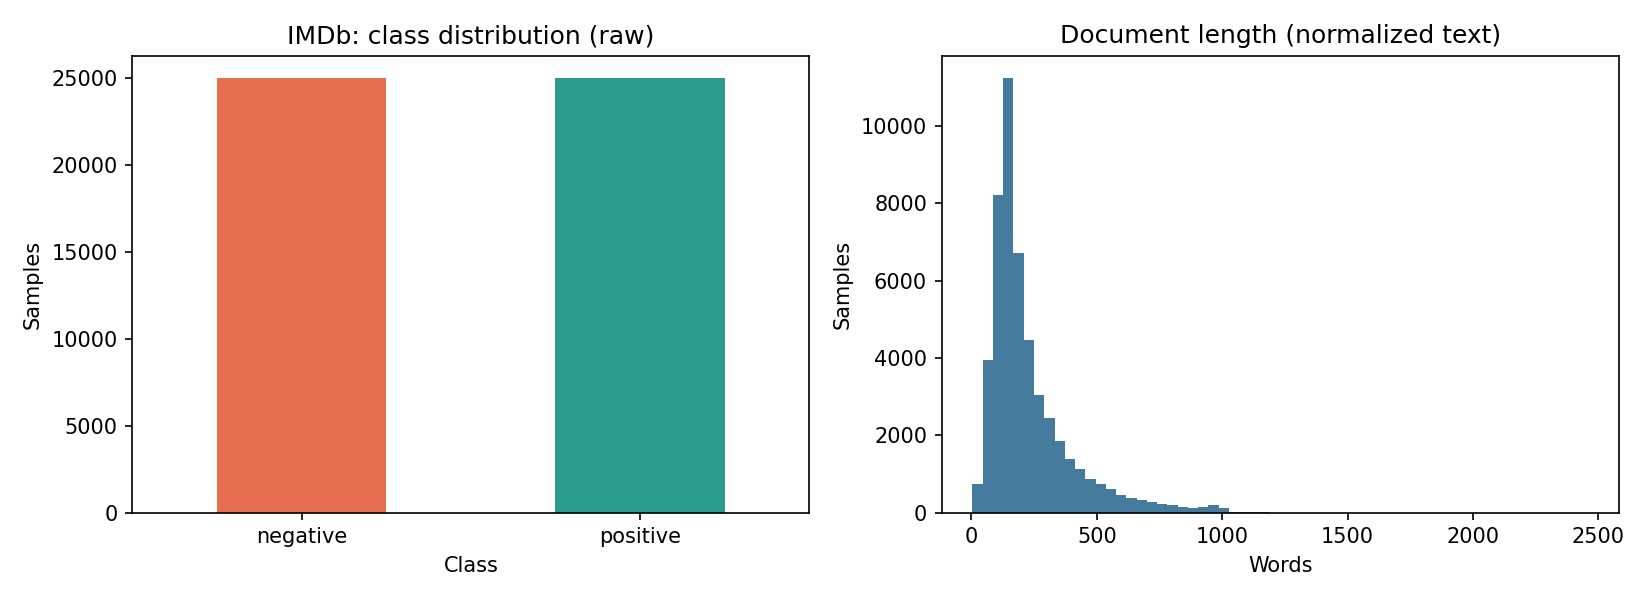

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts.plot.bar(ax=axes[0], color=["#e76f51", "#2a9d8f"], rot=0)
axes[0].set(title="IMDb: class distribution (raw)", xlabel="Class", ylabel="Samples")
lengths = raw["review"].fillna("").map(normalize_text).str.split().str.len()
axes[1].hist(lengths, bins=60, color="#457b9d")
axes[1].set(title="Document length (normalized text)", xlabel="Words", ylabel="Samples")
fig.tight_layout()
fig.savefig("data/dataset_distribution.png", dpi=150)
display(Image(filename="data/dataset_distribution.png"))
plt.close(fig)

## 2. Chia dữ liệu 60/20/20

In [4]:
display(summary.round({"percentage": 4}))
for left, right in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    overlap = set(splits[left]["text"]) & set(splits[right]["text"])
    print(f"{left} / {right}: {len(overlap)} nội dung trùng")
    assert not overlap
assert len(train) + len(validation) + len(test) == len(cleaned)
print("Đã kiểm tra đủ số mẫu và không trùng nội dung giữa các tập.")

,split,samples,percentage,negative,positive
0,train,29746,59.9984,14817,14929
1,validation,9916,20.0008,4939,4977
2,test,9916,20.0008,4940,4976


train / validation: 0 nội dung trùng
train / test: 0 nội dung trùng
validation / test: 0 nội dung trùng
Đã kiểm tra đủ số mẫu và không trùng nội dung giữa các tập.


## 3. Chạy thí nghiệm

Đặt `RUN_EXPERIMENTS = True` để train lại toàn bộ; mặc định đọc kết quả đã chạy.

In [5]:
import os
import subprocess
import sys
import json
from IPython.display import Image

RUN_EXPERIMENTS = False
if RUN_EXPERIMENTS:
    environment = dict(os.environ, PYTHONHASHSEED="42")
    subprocess.run([sys.executable, "experiments.py"], check=True, env=environment)

artifacts = Path("artifacts")
results = pd.read_csv("results.csv")
validation_results = pd.read_csv(artifacts / "validation_results.csv")
selected = pd.read_csv(artifacts / "selected_configs.csv")
selection = json.loads((artifacts / "selection.json").read_text())
print("Chọn bằng validation:", selection["winner"])


Chọn bằng validation: tfidf_bi_50k_LR


## 4. Baseline — TF-IDF + Logistic Regression

In [6]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

baseline_c = selected.loc[selected["model"].eq("tfidf_uni_20k_LR"), "C"].iloc[0]
vectorizer = TfidfVectorizer(max_features=20000, min_df=2, dtype=np.float32)
x_train = vectorizer.fit_transform(train["text"])
x_validation = vectorizer.transform(validation["text"])
x_test = vectorizer.transform(test["text"])

baseline = LogisticRegression(C=baseline_c, solver="liblinear", max_iter=2000, random_state=42)
with threadpool_limits(limits=2):
    baseline.fit(x_train, train["label"])
predicted = baseline.predict(x_test)

columns = ["model", "C", "vocabulary_size", "feature_dimensions", "training_seconds",
           "accuracy", "precision", "recall", "f1", "macro_f1"]
display(results.loc[results["model"].eq("tfidf_uni_20k_LR"), columns])

,model,C,vocabulary_size,feature_dimensions,training_seconds,accuracy,precision,recall,f1,macro_f1
1,tfidf_uni_20k_LR,2.0,20000,20000,3.414193,0.898144,0.886851,0.913585,0.90002,0.898109


## 5. So sánh representation

Bảng 1: validation, cùng C=1. Bảng 2: test, C chọn bằng validation.

TF-IDF giữ tín hiệu từ vựng; lấy trung bình Word2Vec có thể làm loãng thông tin.

In [7]:
display(pd.read_csv(artifacts / "representation_comparison_c1.csv")[columns])
comparison_models = ["tfidf_uni_20k_LR", "avg_word2vec_LR", "tfidf_uni_20k_SVM"]
display(results.loc[results["model"].isin(comparison_models), columns])
display(pd.read_csv(artifacts / "word2vec_coverage.csv"))

,model,C,vocabulary_size,feature_dimensions,training_seconds,accuracy,precision,recall,f1,macro_f1
0,tfidf_uni_20k_LR,1.0,20000,20000,3.333112,0.889572,0.876601,0.907776,0.891916,0.889520
1,tfidf_uni_20k_SVM,1.0,20000,20000,3.709095,0.891085,0.881984,0.903958,0.892836,0.891056
2,avg_word2vec_LR,1.0,54058,100,121.671434,0.859217,0.852114,0.870605,0.861260,0.859187


,model,C,vocabulary_size,feature_dimensions,training_seconds,accuracy,precision,recall,f1,macro_f1
1,tfidf_uni_20k_LR,2.0,20000,20000,3.414193,0.898144,0.886851,0.913585,0.900020,0.898109
2,tfidf_uni_20k_SVM,0.5,20000,20000,3.648629,0.901775,0.892045,0.914992,0.903373,0.901748
6,avg_word2vec_LR,2.0,54058,100,121.809200,0.865672,0.859086,0.876005,0.867463,0.865647


,split,tokens,known_tokens,token_coverage,zero_vector_documents
0,train,6844596,6810296,0.994989,0
1,validation,2281338,2260008,0.990650,0
2,test,2272846,2251645,0.990672,0


## 6. Phủ định — good / not good

Bigram giữ được một số cụm phủ định, nhưng chưa xử lý mọi trường hợp.

In [8]:
display(pd.read_csv(artifacts / "negation_predictions.csv"))
display(pd.read_csv(artifacts / "negation_similarity.csv"))

,model,text,predicted,p_positive
0,tfidf_uni_20k_LR,this movie is good,positive,0.867317
1,tfidf_uni_20k_LR,this movie is not good,positive,0.579183
2,tfidf_uni_20k_LR,this movie is bad,negative,0.001157
3,tfidf_uni_20k_LR,this movie is not bad,negative,0.000637
4,tfidf_bi_50k_LR,this movie is good,positive,0.800733
5,tfidf_bi_50k_LR,this movie is not good,negative,0.085647
6,tfidf_bi_50k_LR,this movie is bad,negative,0.009588
7,tfidf_bi_50k_LR,this movie is not bad,negative,0.043595
8,avg_word2vec_LR,this movie is good,positive,0.947560
9,avg_word2vec_LR,this movie is not good,negative,0.490122


,model,pair,cosine_similarity
0,tfidf_uni_20k_LR,good / not good,0.886910
1,tfidf_bi_50k_LR,good / not good,0.418091
2,avg_word2vec_LR,good / not good,0.981246


## 7. Unigram và unigram + bigram

Bigram bổ sung thông tin cụm từ, đổi lại cần nhiều đặc trưng hơn.

In [9]:
display(results.loc[results["model"].isin(["tfidf_uni_50k_LR", "tfidf_bi_50k_LR"]), columns])

,model,C,vocabulary_size,feature_dimensions,training_seconds,accuracy,precision,recall,f1,macro_f1
3,tfidf_uni_50k_LR,2.0,48544,48544,3.331947,0.898850,0.888671,0.912781,0.900565,0.898820
4,tfidf_bi_50k_LR,2.0,50000,50000,12.299203,0.908128,0.898451,0.921021,0.909596,0.908104


## 8. Vocabulary size và stopwords — validation

Vocabulary lớn hơn hoặc bỏ stopwords không đảm bảo kết quả tốt hơn.

In [10]:
vocabulary_models = ["tfidf_uni_5k_LR", "tfidf_uni_20k_LR", "tfidf_uni_50k_LR"]
display(selected.loc[selected["model"].isin(vocabulary_models), columns])
display(selected.loc[selected["model"].isin(["tfidf_uni_20k_LR", "tfidf_uni_20k_stop_LR"]), columns])

,model,C,vocabulary_size,feature_dimensions,training_seconds,accuracy,precision,recall,f1,macro_f1
0,tfidf_uni_5k_LR,2.0,5000,5000,3.581512,0.886547,0.875292,0.902552,0.888713,0.886504
1,tfidf_uni_20k_LR,2.0,20000,20000,3.414193,0.893808,0.881861,0.910388,0.895897,0.893765
3,tfidf_uni_50k_LR,2.0,48544,48544,3.331947,0.894514,0.882467,0.911191,0.896599,0.894471


,model,C,vocabulary_size,feature_dimensions,training_seconds,accuracy,precision,recall,f1,macro_f1
1,tfidf_uni_20k_LR,2.0,20000,20000,3.414193,0.893808,0.881861,0.910388,0.895897,0.893765
5,tfidf_uni_20k_stop_LR,2.0,20000,20000,2.774409,0.889572,0.877333,0.906771,0.891809,0.889525


## 9. Đánh giá trên test


,model,C,vocabulary_size,feature_dimensions,training_seconds,accuracy,precision,recall,f1,macro_f1
0,tfidf_uni_5k_LR,2.0,5000,5000,3.581512,0.893203,0.885911,0.903537,0.894637,0.893183
1,tfidf_uni_20k_LR,2.0,20000,20000,3.414193,0.898144,0.886851,0.913585,0.900020,0.898109
2,tfidf_uni_20k_SVM,0.5,20000,20000,3.648629,0.901775,0.892045,0.914992,0.903373,0.901748
3,tfidf_uni_50k_LR,2.0,48544,48544,3.331947,0.898850,0.888671,0.912781,0.900565,0.898820
4,tfidf_bi_50k_LR,2.0,50000,50000,12.299203,0.908128,0.898451,0.921021,0.909596,0.908104
5,tfidf_uni_20k_stop_LR,2.0,20000,20000,2.774409,0.895522,0.884315,0.910973,0.897446,0.895486
6,avg_word2vec_LR,2.0,54058,100,121.809200,0.865672,0.859086,0.876005,0.867463,0.865647


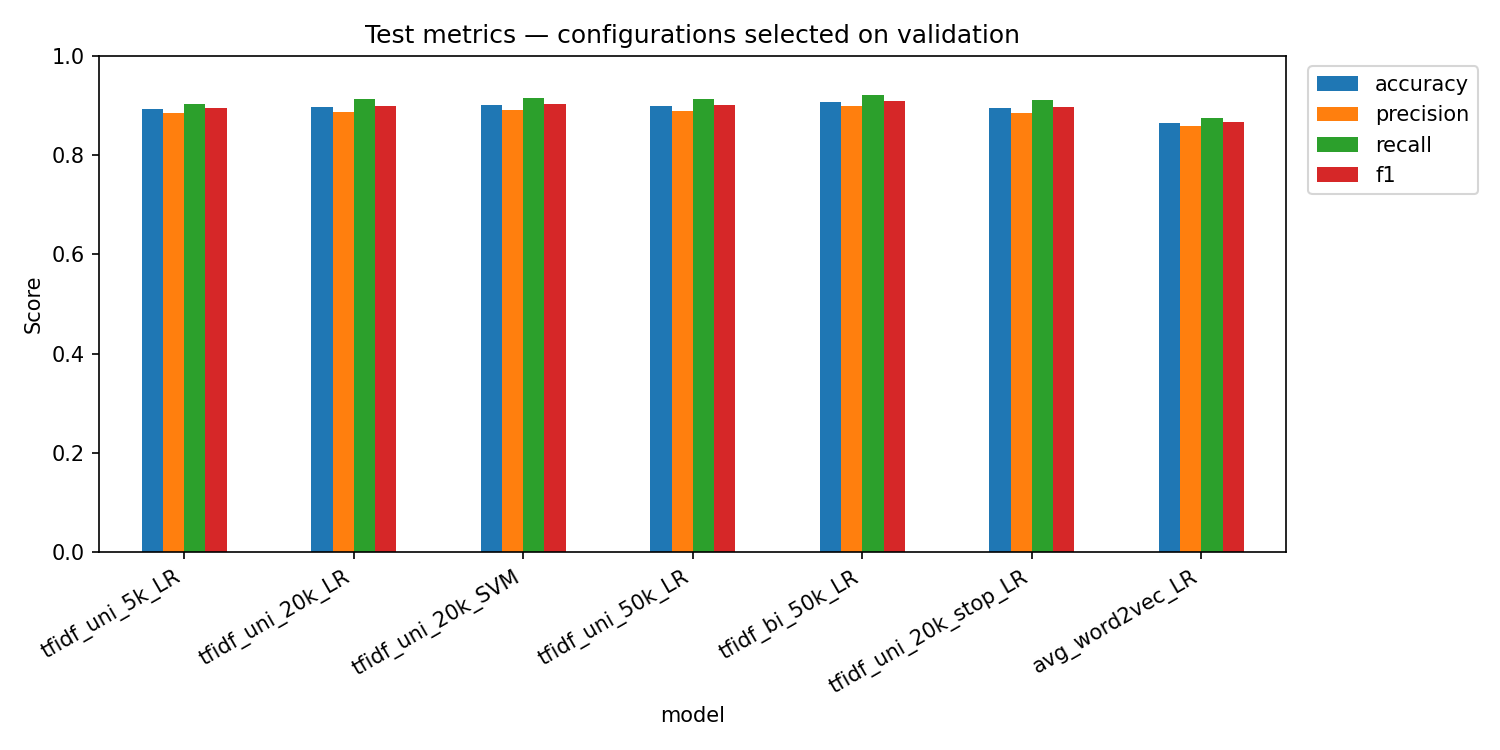

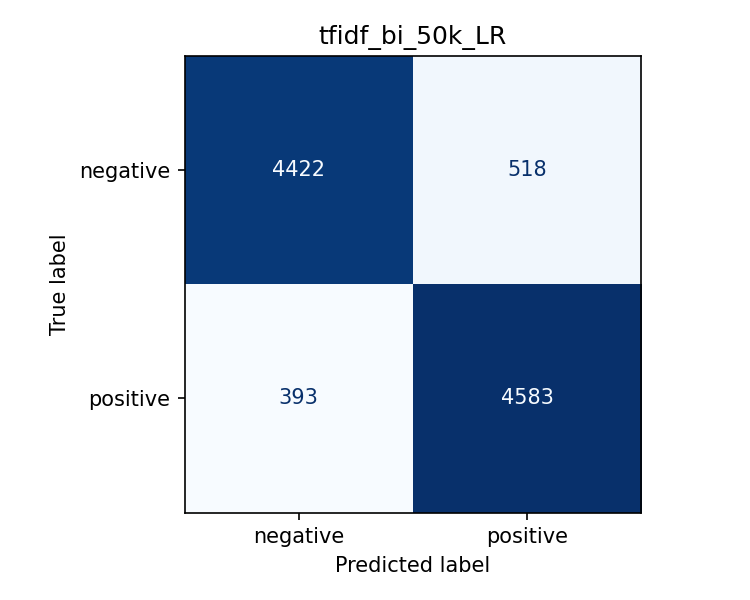

,precision,recall,f1-score,support
negative,0.918380,0.895142,0.906612,4940.000000
positive,0.898451,0.921021,0.909596,4976.000000
accuracy,0.908128,0.908128,0.908128,0.908128
macro avg,0.908416,0.908081,0.908104,9916.000000
weighted avg,0.908379,0.908128,0.908109,9916.000000


In [11]:
display(results[columns])
display(Image(filename=str(artifacts / "model_comparison.png")))
display(Image(filename="confusion_matrix.png"))
report_path = artifacts / f"classification_report_{selection['winner']}.json"
display(pd.DataFrame(json.loads(report_path.read_text())).T)

In [12]:
examples = pd.read_csv(artifacts / "error_examples.csv")
with pd.option_context("display.max_colwidth", 180):
    display(examples)
assert examples["correct"].sum() == 3
assert (~examples["correct"]).sum() == 3

,source_id,review,label,predicted,correct
0,14141,Post 1988 after the disaster GJS Amitabh's films lost the quality they had earlier <br /><br />Barring MAIN AZAAD HOON released in 1989 which was a great film rest all films we...,negative,negative,True
1,4254,"The first 20 minutes were a little fun because I don't think I've seen a film this bad before {acting, script, effects (!), etc....} The rest of the running time seemed to drag...",negative,negative,True
2,9212,I'm a dance teacher and was looking forward to some good dance routines in this film. How sad to have been subjected to such a painful experience. <br /><br />I had major probl...,negative,negative,True
3,44794,"This movie wasn't the best... but it did have some good actors in it. Isiaiah Washington was pretty good as a homeless guy, Guy Torrey was good as his handicapped brother, Ice-...",negative,positive,False
4,33874,"This TV film tells the story of extrovert Frannie suddenly returning to Silk Hope to visit friends and family, but unaware of her mother's death. Her sister runs the family hom...",negative,positive,False
5,21480,"My title above says it all. Let me make it clearer. If you have seen the BBC's ""Planet Earth"" , which I am sure most of you have , then you are not gonna like this movie too mu...",negative,positive,False


## 11. Top features

Các feature phần lớn phù hợp sentiment; trọng số còn phụ thuộc dữ liệu.

In [13]:
weights = pd.read_csv(artifacts / "top_features.csv")
for model_name, group in weights.groupby("model", sort=False):
    print(model_name)
    positive = group.loc[group["direction"].eq("positive"), ["feature", "weight"]].head(10).reset_index(drop=True)
    negative = group.loc[group["direction"].eq("negative"), ["feature", "weight"]].head(10).reset_index(drop=True)
    display(pd.concat({"positive": positive, "negative": negative}, axis=1))

tfidf_uni_20k_LR


positive            negative           
     feature    weight   feature     weight
0      great  9.297010     worst -11.993551
1  excellent  8.102139       bad  -8.902036
2    amazing  6.227845     awful  -8.740933
3       best  6.068202    boring  -8.467180
4    perfect  5.997231     waste  -8.247782
5  wonderful  5.037099      poor  -7.159614
6   favorite  5.016294  terrible  -6.700394
7      today  4.915356     worse  -6.211561
8    enjoyed  4.846899   nothing  -6.136499
9  brilliant  4.789548  horrible  -6.046385

tfidf_bi_50k_LR


positive             negative          
     feature    weight    feature    weight
0      great  9.644209        bad -9.397012
1  excellent  7.301428      worst -9.196778
2    amazing  5.740078      awful -8.128312
3    perfect  5.405669     boring -7.808094
4  wonderful  4.853069  the worst -7.323565
5        fun  4.778276       poor -6.820326
6       best  4.712382      waste -6.489475
7   the best  4.579242   terrible -6.344671
8  brilliant  4.477123    nothing -5.587739
9      today  4.447969      worse -5.583273

## 12. Demo sentiment

In [14]:
from predict import predict_reviews
reviews = [
    "I loved this movie. The acting was excellent and the story was engaging.",
    "This movie was boring and the acting was terrible.",
]
display(pd.DataFrame(predict_reviews(reviews)))

,review,predicted,model,p_positive
0,I loved this movie. The acting was excellent a...,positive,tfidf_bi_50k_LR,0.972496
1,This movie was boring and the acting was terri...,negative,tfidf_bi_50k_LR,0.002682
